**About:** ASCENT / NETr — contrastive node embeddings, end to end

Walks the pipeline in the order it runs: a frame and its detections, the two
augmented views those detections are learned from, the patches the network
actually consumes, a forward pass, and finally the only number that matters —
does a cell's embedding retrieve its own next frame?

The paper's model is trained with **no annotation**, and ground truth appears
exactly once, at the end, to score it. The run's `real_prop` says how much of
that held: above 0, some fraction of the training pairs are real consecutive
frames matched by the ground-truth graph, scored on the ~1 cell a frame it
annotates.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd ../src

/data/kaggle-cell-tracking/src


In [3]:
import glob
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from embeddings.augment import resolve_aug_cfg, sample_view, apply_photometric
from embeddings.dataset import EmbeddingDataset
from embeddings.eval import _attach, _embed_frame, _gt_frames, evaluate_retrieval
from embeddings.match import link_sequence, match_frames
from embeddings.losses import nt_xent
from embeddings.model import NETr
from embeddings.patches import extract_patches, normalise_coords, normalise_frame
from params import SCALE
from utils.plot import scatter_by_depth

### Configuration

In [4]:
# Any preds folder the tracking pipeline wrote. These detections define the
# crops -- the nodes the matcher will really be asked to link, spurious ones
# included, which is the point of training on them rather than on ground truth.
COORDS_DIR = "../logs/2026-09-02/0/preds_0.50/"
DATA_DIR = "../input/train/"
SAMPLE = "44b6_0113de3b"
FRAME = 0

VOXEL = SCALE                      # (1.625, 0.40625, 0.40625) um
PATCH_ZYX = (3, 64, 64)            # the paper's, z-slices as backbone channels
N_FRAMES = 3                       # contiguous z-slabs per cell, averaged after
                                   # the backbone (overridden by the checkpoint below)

coords_all = np.load(Path(COORDS_DIR) / f"{SAMPLE}.npz")["coords"]
coords = coords_all[coords_all[:, 0].astype(int) == FRAME][:, 1:4].astype(np.float32)

import zarr
volume_raw = np.asarray(zarr.open_group(f"{DATA_DIR}{SAMPLE}.zarr", mode="r")["0"][FRAME])
volume = normalise_frame(volume_raw)     # the paper's 1st/99.99th percentile rescale

print(f"{SAMPLE} t={FRAME}  |  volume {volume.shape}  |  {len(coords)} detections")
print(f"intensity after frame normalisation: {volume.min():.3f} .. {volume.max():.3f}")

44b6_0113de3b t=0  |  volume (64, 256, 256)  |  214 detections
intensity after frame normalisation: 0.000 .. 1.000


### 1. The frame and its detections

`scatter_by_depth` fades a marker with its distance from the displayed slice, so
the cells actually *in* this section read boldly and the rest stay as context.
A nucleus spans only 2-4 z-slices here, so at a wide tolerance most circles are
legitimately out of plane.

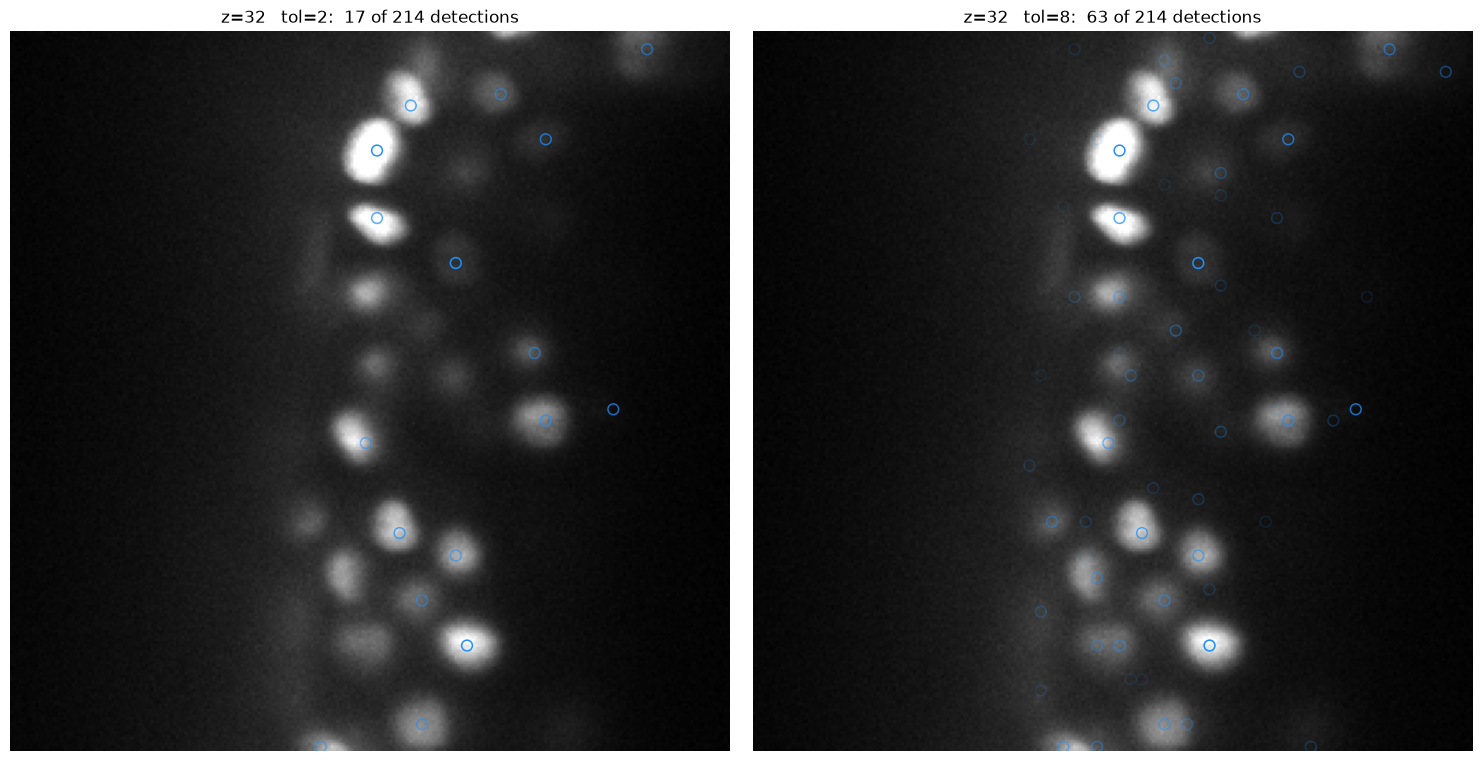

In [5]:
zc = int(np.median(coords[:, 0]))
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, tol in zip(axes, (2, 8)):
    ax.imshow(volume[zc], cmap="gray", vmax=np.percentile(volume, 99.5))
    near = scatter_by_depth(ax, coords, zc, "dodgerblue", tol=tol, s=60, linewidths=1.1)
    ax.set_title(f"z={zc}   tol={tol}:  {int(near.sum())} of {len(coords)} detections")
    ax.axis(False)
plt.tight_layout(); plt.show()

### 2. The two augmented views

This is the entire supervision signal: two views of one frame, and a cell's
identity is whatever survives both. Geometry (rotation, scale, elastic) is drawn
once per view and shared by every cell in it -- a view is the same scene imaged
differently, not a bag of independently warped cells.

The frames below are rendered by pushing the *whole slice* through the same
sampling code the patches use, so what you see is exactly the transform the
patches were cut under. Scattered on top are each view's own jittered
coordinates.

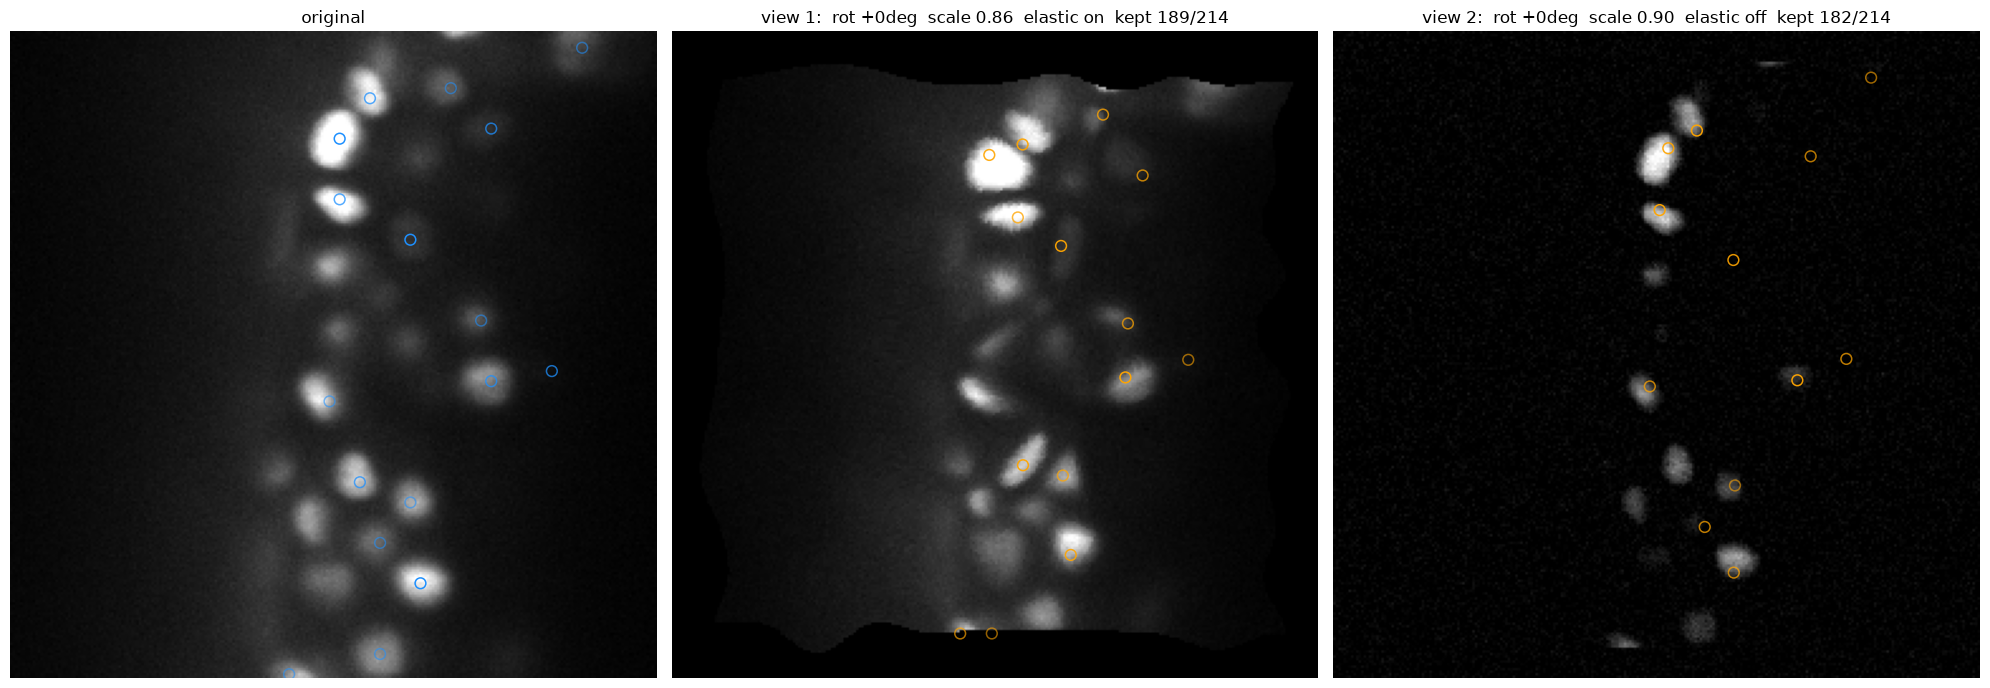

cells kept by both views: 163 of 214  (object dropout removes the rest)
position jitter between views: median 2.56 um, max 5.79 um   (cells sit ~8 um apart)

intensity under the markers (geometry only)   background 0.077
  original frame, view-1 coords               0.345   <- the target
  warped view, coords NOT mapped              0.149
  warped view, coords mapped                  0.297


In [6]:
AUG = resolve_aug_cfg(None)        # the defaults from embeddings/augment.py
rng = np.random.default_rng(0)


def render_view(vol, z, view, rng):
    """The whole slice under a view's geometry.

    Reuses extract_patches by asking for one patch the size of the frame, so
    the visualisation cannot drift from what the patches actually get.
    """
    Y, X = vol.shape[1:]
    centre = np.array([[z, (Y - 1) / 2, (X - 1) / 2]], np.float32)
    big = extract_patches(vol, centre, (1, Y, X), angle_deg=view["angle"],
                          scale=view["scale"], elastic=view["elastic"])
    # (N, n_frames, pz, py, px) -- one cell, one slab, one slice.
    return apply_photometric(big, view["photo"], rng)[0, 0, 0]


def map_coords_to_view(p, view, shape_yx, iters=2):
    """Where an input point ends up in the rendered view.

    The rendered frame is warped but the detections are not, so scattering the
    raw coordinates over it puts every circle in the wrong place -- the marker
    for a cell lands wherever that cell *used* to be. They have to go through
    the same geometry.

    extract_patches maps an output position g to the input it samples:
    ``g -> rotate_scale(g - centre) + centre + d(...)``. Inverting it means
    undoing the elastic displacement first (it is applied last), then the
    rotation and scale about the frame centre. The elastic inverse has no
    closed form -- d is evaluated at the *displaced* point -- so it is solved
    by fixed-point iteration; two passes are enough here, and one is visibly
    short when the field is large.
    """
    Y, X = shape_yx
    centre = np.array([(Y - 1) / 2, (X - 1) / 2], np.float32)
    q = p[:, 1:3].astype(np.float32).copy()

    if view["elastic"] is not None:
        u = q.copy()
        for _ in range(iters):
            iy = np.clip(np.rint(u[:, 0]).astype(int), 0, Y - 1)
            ix = np.clip(np.rint(u[:, 1]).astype(int), 0, X - 1)
            u = q - np.stack([view["elastic"][0][iy, ix],
                              view["elastic"][1][iy, ix]], 1)
        q = u

    d = q - centre
    th, s = np.deg2rad(view["angle"]), view["scale"]
    cos, sin = np.cos(th), np.sin(th)
    out = p.copy()
    out[:, 1] = centre[0] + s * (cos * d[:, 0] + sin * d[:, 1])
    out[:, 2] = centre[1] + s * (-sin * d[:, 0] + cos * d[:, 1])
    return out


views = [sample_view(coords, AUG, rng, VOXEL, volume.shape[1:]) for _ in range(2)]

fig, axes = plt.subplots(1, 3, figsize=(20, 6.8))
axes[0].imshow(volume[zc], cmap="gray", vmax=np.percentile(volume, 99.5))
scatter_by_depth(axes[0], coords, zc, "dodgerblue", tol=2, s=60, linewidths=1.1)
axes[0].set_title("original")

rendered = []
for ax, (k, v) in zip(axes[1:], enumerate(views)):
    img = render_view(volume, zc, v, rng)
    rendered.append(img)
    ax.imshow(img, cmap="gray", vmax=np.percentile(volume, 99.5))
    scatter_by_depth(ax, map_coords_to_view(v["coords"], v, volume.shape[1:]),
                     zc, "orange", tol=2, s=60, linewidths=1.1)
    ax.set_title(f"view {k + 1}:  rot {v['angle']:+.0f}deg  scale {v['scale']:.2f}  "
                 f"elastic {'on' if v['elastic'] is not None else 'off'}  "
                 f"kept {int(v['keep'].sum())}/{len(coords)}")
for ax in axes:
    ax.axis(False)
plt.tight_layout(); plt.show()

both = views[0]["keep"] & views[1]["keep"]
dj = (views[0]["coords"] - views[1]["coords"]) * np.asarray(VOXEL)
print(f"cells kept by both views: {int(both.sum())} of {len(coords)}  "
      f"(object dropout removes the rest)")
print(f"position jitter between views: median {np.median(np.linalg.norm(dj, axis=1)):.2f} um, "
      f"max {np.linalg.norm(dj, axis=1).max():.2f} um   (cells sit ~8 um apart)")

# The markers have to sit on cells, not near them, and that is checkable rather
# than a matter of squinting: read the image where each marker landed. On cells
# it should look like the original frame does; a wrong mapping reads background.
#
# The check renders geometry *without* the photometric jitter. Brightness,
# contrast and gamma move the intensities on their own, so comparing against
# the original frame through them would confound "the markers are in the wrong
# place" with "the view is simply dimmer".
def _at(im, c):
    iy = np.clip(np.rint(c[:, 1]).astype(int), 0, im.shape[0] - 1)
    ix = np.clip(np.rint(c[:, 2]).astype(int), 0, im.shape[1] - 1)
    return im[iy, ix]

v0 = views[0]
geom_only = extract_patches(
    volume,
    np.array([[zc, (volume.shape[1] - 1) / 2, (volume.shape[2] - 1) / 2]], np.float32),
    (1, *volume.shape[1:]),
    angle_deg=v0["angle"], scale=v0["scale"], elastic=v0["elastic"],
)[0, 0, 0]
near = np.abs(v0["coords"][:, 0] - zc) <= 2

print()
print(f"intensity under the markers (geometry only)   background {volume[zc].mean():.3f}")
print(f"  original frame, view-1 coords               "
      f"{_at(volume[zc], v0['coords'][near]).mean():.3f}   <- the target")
print(f"  warped view, coords NOT mapped              "
      f"{_at(geom_only, v0['coords'][near]).mean():.3f}")
print(f"  warped view, coords mapped                  "
      f"{_at(geom_only, map_coords_to_view(v0['coords'], v0, volume.shape[1:])[near]).mean():.3f}")

#### What the network actually sees

Patches, not frames. Each column is one cell under the two views. If a pair ever
showed two *different* cells the loss would be learning a falsehood — which is
why the jitter is bounded rather than Gaussian.

patches: (214, 3, 3, 64, 64) = (cells, slabs, z per slab, y, x)


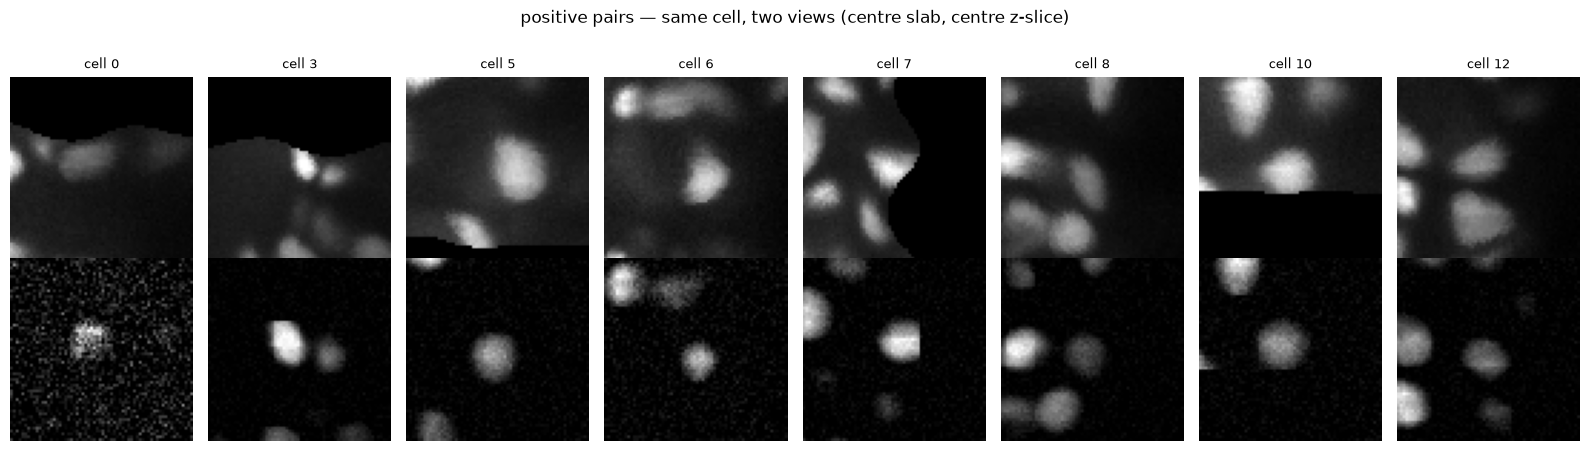

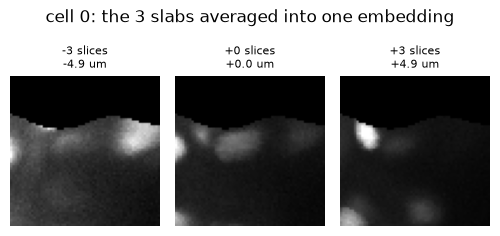

In [7]:
p1, p2 = (
    apply_photometric(
        extract_patches(volume, v["coords"], PATCH_ZYX, v["angle"], v["scale"],
                        v["elastic"], n_frames=N_FRAMES), v["photo"], rng)
    for v in views
)
print("patches:", p1.shape, "= (cells, slabs, z per slab, y, x)")

show = np.flatnonzero(both)[:8]
fig, axes = plt.subplots(2, len(show), figsize=(2.0 * len(show), 4.4))
mid_slab, mid_z = N_FRAMES // 2, PATCH_ZYX[0] // 2
for col, i in enumerate(show):
    for row, patches in enumerate((p1, p2)):
        axes[row, col].imshow(patches[i, mid_slab, mid_z], cmap="gray")
        axes[row, col].axis(False)
    axes[0, col].set_title(f"cell {i}", fontsize=9)
axes[0, 0].set_ylabel("view 1"); axes[1, 0].set_ylabel("view 2")
plt.suptitle("positive pairs — same cell, two views (centre slab, centre z-slice)", y=1.02)
plt.tight_layout(); plt.show()

# The z-slabs of one cell. The centre slab is exactly the patch a single-slab
# model would have seen; the rest are the context this representation adds, and
# a slab that ran off the end of the stack is black.
if N_FRAMES > 1:
    i = show[0]
    fig, axes = plt.subplots(1, N_FRAMES, figsize=(1.7 * N_FRAMES, 2.2))
    for f, ax in enumerate(axes):
        ax.imshow(p1[i, f, mid_z], cmap="gray")
        off = (f - mid_slab) * PATCH_ZYX[0]
        ax.set_title(f"{off:+d} slices\n{off * VOXEL[0]:+.1f} um", fontsize=8)
        ax.axis(False)
    plt.suptitle(f"cell {i}: the {N_FRAMES} slabs averaged into one embedding", y=1.06)
    plt.tight_layout(); plt.show()

### 3. The model, and one batch through it

In [10]:
# Pinned to the run the fusion numbers below were measured on. Set it to None
# to take the most recently *finished* run instead -- a run still training has
# no ckpt_final.pt, so its half-trained weights are skipped rather than silently
# making every number here worse.
CKPT = "../logs/2026-09-03/13/fold_0/ckpt_final.pt"

CKPT = CKPT or sorted(glob.glob("../logs/*/*/fold_*/ckpt_final.pt"), key=os.path.getmtime)[-1]
CKPT_DIR = Path(CKPT).parent
cfg = json.load(open(CKPT_DIR.parent / "args.json"))
print(CKPT)

# Rebuilt from the checkpoint's own model_config rather than from the constants
# at the top: patch size and the two branch flags change between runs, and a
# mismatch here is not a graceful degradation -- a model built with the wrong
# patch size loads its ViT position embedding at the wrong shape and raises,
# and one built with a branch the run ablated away raises on the missing keys.
state = torch.load(CKPT, map_location="cpu", weights_only=True)
mc = state.get("model_config", {})
PATCH_ZYX_CFG = PATCH_ZYX                      # what the cells above drew
PATCH_ZYX = tuple(mc.get("patch_zyx", PATCH_ZYX))
# Absent from checkpoints written before z-slabs existed, and 1 is what
# those runs did. It changes no parameter, so a wrong value here loads
# cleanly and silently embeds the wrong thing -- hence the default.
N_FRAMES = int(mc.get("n_frames", 1) or 1)
model = NETr(
    d_model=int(mc.get("d_model", 256)),
    n_layers=int(mc.get("n_layers", 4)),
    n_heads=int(mc.get("n_heads", 4)),
    dim_feedforward=int(mc.get("dim_feedforward", 512)),
    dropout=float(mc.get("dropout", 0.1)),
    patch_z=PATCH_ZYX[0], patch_size=PATCH_ZYX[1],
    embed_dim=mc.get("embed_dim"),
    backbone=mc.get("backbone", "vit_small_patch16_224.dino"),
    pretrained=False,
    use_visual=bool(mc.get("use_visual", True)),
    use_position=bool(mc.get("use_position", True)),
)
model.load_state_dict(state["model_state_dict"])
model = model.cuda().eval()

# The detections the run was trained against, which is not necessarily the
# COORDS_DIR set at the top -- the evaluation below uses the run's own.
EVAL_COORDS = cfg.get("coords_log_folder", COORDS_DIR)
branches = "+".join(b for b, on in (("visual", model.use_visual),
                                    ("position", model.use_position)) if on)
span = N_FRAMES * PATCH_ZYX[0]
print(f"NETr [{branches}]  patch {PATCH_ZYX} x {N_FRAMES} slab(s)"
      f"  ->  {span} z-slices, {span * 1.625:.1f} um"
      f"  |  {model.count_parameters() / 1e6:.1f}M parameters")
print(f"detections: {EVAL_COORDS}")
if tuple(mc.get("patch_zyx", ())) not in ((), PATCH_ZYX_CFG):
    print(f"note: the cells above visualised {PATCH_ZYX_CFG} patches; this run "
          f"used {PATCH_ZYX}, and everything below follows the checkpoint")

../logs/2026-09-03/13/fold_0/ckpt_final.pt
NETr [visual]  patch (3, 48, 48) x 1 slab(s)  ->  3 z-slices, 4.9 um  |  23.8M parameters
detections: ../logs/2026-09-02/9/preds_0.50/
note: the cells above visualised (3, 32, 32) patches; this run used (3, 48, 48), and everything below follows the checkpoint


In [12]:
# patch_zyx has to be the checkpoint's, not the display default set at the top:
# the ViT asserts on its input size, so a mismatch is an exception rather than a
# quietly worse number.
#
# real_prop mixes in *real* (t, t+1) pairs, linked by the ground-truth graph,
# alongside the two-views-of-one-frame pairs above. Building the dataset with it
# on reads every video's geff once (~0.1 s each), so this cell is slower than
# the rest.
ds = EmbeddingDataset(EVAL_COORDS, DATA_DIR, embryos=[SAMPLE.split("_")[0]],
                      max_nodes=128, max_frames=4, patch_zyx=PATCH_ZYX,
                      n_frames=N_FRAMES, real_prop=cfg.get("real_prop", 0.0))
batch = torch.utils.data.default_collate([ds[i] for i in range(4)])
print("batch:", {k: tuple(v.shape) for k, v in batch.items() if hasattr(v, "shape")})

with torch.no_grad():
    z1 = model(batch["patches_1"].cuda().float(), batch["coords_1"].cuda().float(), batch["mask_1"].cuda())
    z2 = model(batch["patches_2"].cuda().float(), batch["coords_2"].cuda().float(), batch["mask_2"].cuda())
out = nt_xent(z1.float(), z2.float(),
              batch["mask_1"].cuda(), batch["mask_2"].cuda(),
              batch["pos_1to2"].cuda(), batch["pos_2to1"].cuda(), temperature=0.05)
print(f"embeddings {tuple(z1.shape)}  |  unit norm "
      f"{float(z1[batch['mask_1']].norm(dim=-1).mean()):.4f}")
print(f"NT-Xent loss {float(out.loss):.4f}   top1 {float(out.top1):.4f}   "
      f"over {int(out.n_pairs)} scored rows")

# Where the supervision comes from, sample by sample. A real pair scores only
# its annotated links -- a couple of rows against a synthetic pair's few
# hundred -- which is exactly why the loss averages per *pair* and not per row.
for name, real, rows in zip(batch["name"], batch["is_real"], out.sample_rows):
    print(f"  {name:<24} {'real (t, t+1)' if real else 'two views of t':<16} "
          f"{int(rows):>4} scored rows")

batch: {'patches_1': (4, 128, 1, 3, 48, 48), 'patches_2': (4, 128, 1, 3, 48, 48), 'coords_1': (4, 128, 3), 'coords_2': (4, 128, 3), 'mask_1': (4, 128), 'mask_2': (4, 128), 'pos_1to2': (4, 128), 'pos_2to1': (4, 128), 'is_real': (4,)}
embeddings (4, 128, 256)  |  unit norm 1.0000
NT-Xent loss 0.0064   top1 1.0000   over 818 scored rows
  44b6_0113de3b_t0         two views of t    222 scored rows
  44b6_0113de3b_t1         two views of t    206 scored rows
  44b6_0113de3b_t2         two views of t    200 scored rows
  44b6_0113de3b_t3         two views of t    190 scored rows


### 4. Inference and evaluation

The view-to-view top-1 above only says the embeddings are stable under the
transforms they were trained on. The number that matters uses ground truth:
embed frame `t` and `t+1`, rank every detection at `t+1` by cosine similarity,
and count a hit when the top-ranked one is the cell the GT graph links to.

Everything from here on reads **precomputed** embeddings written by
`inference_contrastive.py`, so nothing below opens a zarr or runs the ViT. That
is the whole reason these cells can score entire videos and a whole embryo in
seconds, where recomputing capped the same numbers at three videos and six
frames.

Reported alongside top-1 is the **nearest-neighbour baseline**: link each cell to
the spatially closest detection at `t+1`, no model involved. Cells move ~1.86 um
a frame against ~8 um of spacing, so geometry alone is very nearly sufficient and
this is not a low bar. `delta` is the number that says whether appearance added
anything at all.

`coverage` is the share of GT links whose *both* endpoints had a detection within
7 um. It is the ceiling the detector puts on this metric -- a link with no
detection is a detection failure, not an embedding one, so it is reported rather
than counted as a miss.

In [26]:
from tracking.main import _paths_for_embryos

In [27]:
class Embeddings:
    """``(sample, t)`` -> ``(coords (N, 3), embeddings (N, D))``.

    One npz per video, read once and kept: a video is a few tens of MB and the
    cells below sweep over its frames repeatedly.
    """

    def __init__(self, folder):
        self.folder = Path(folder)
        self._cache = {}

    def video(self, sample):
        hit = self._cache.get(sample)
        if hit is None:
            with np.load(self.folder / f"{sample}.npz") as d:
                hit = (d["coords"].astype(np.float32),
                       d["embeddings"].astype(np.float32))
            self._cache[sample] = hit
        return hit

    def frame(self, sample, t):
        coords, emb = self.video(sample)
        rows = coords[:, 0].astype(int) == t
        return coords[rows, 1:4], emb[rows]

    def frames(self, sample):
        return np.unique(self.video(sample)[0][:, 0].astype(int))

    def has(self, sample):
        return (self.folder / f"{sample}.npz").exists()

In [28]:
from tqdm import tqdm


def retrieval(embryo, n_videos=10, match_um=7.0):
    """``embeddings.eval.evaluate_retrieval``, off the npz instead of the model.

    Same definition, so these numbers stay comparable with the training-time
    ones: candidates are *every* detection at ``t+1``, not just the annotated
    handful -- ranking against five alternatives would be trivial and nothing
    like what the matcher faces -- and a GT node is attached to the nearest
    detection within ``match_um``.
    """
    rows = []
    for path in tqdm(_paths_for_embryos(DATA_DIR, [embryo]), total=n_videos):
        if len(rows) >= n_videos or not EMB.has(path.name):
            continue

        gt_nodes, gt_links = _gt_frames(path)
        if not gt_links:
            continue

        hits = nn_hits = scored = attempted = hit_but_not_nn = union = 0

        for t in sorted(gt_links):
            det_t, emb_t = EMB.frame(path.name, t)
            det_n, emb_n = EMB.frame(path.name, t + 1)
            attempted += len(gt_links[t])
            if len(det_t) == 0 or len(det_n) == 0:
                continue

            src = _attach(gt_nodes[t], det_t, match_um)
            tgt = _attach(gt_nodes[t + 1], det_n, match_um)
            usable = [(i, j) for i, j in gt_links[t] if src[i] >= 0 and tgt[j] >= 0]
            if not usable:
                continue

            # Both sides are L2-normalised, so the inner product is the cosine.
            nearest = (emb_t @ emb_n.T).argmax(axis=1)
            dist = np.linalg.norm(
                (det_t[:, None] - det_n[None]) * np.asarray(SCALE, np.float32), axis=2)
            closest = dist.argmin(axis=1)
            
            for i, j in usable:
                hits += int(nearest[src[i]] == tgt[j])
                nn_hits += int(closest[src[i]] == tgt[j])
                hit_but_not_nn += int(nearest[src[i]] != closest[src[i]])
                union += int(nearest[src[i]] == tgt[j] or closest[src[i]] == tgt[j])
                scored += 1

        if scored:
            rows.append({
                "sample": path.name,
                "n_links": scored,
                "top1": hits / scored,
                "top1_nn": nn_hits / scored,
                "hit_but_not_nn": hit_but_not_nn / scored,
                "union": union / scored,
                "delta": (hits - nn_hits) / scored,
                "coverage": scored / max(attempted, 1)
            })
    return rows

In [34]:
EMB_DIR = "../logs/2026-09-03/13/embeddings/"
# EMB_DIR = "../logs/2026-09-03/30/embeddings/"


EMB_RUN = Path(EMB_DIR).parent
emb_cfg = json.load(open(EMB_RUN / "args.json"))
EMB_COORDS = emb_cfg["coords_log_folder"]

In [35]:
EMB = Embeddings(EMB_DIR)
_c, _e = EMB.video(SAMPLE)
print(EMB_DIR)
print(f"  NETr run   : {EMB_RUN.name}  ({emb_cfg.get('backbone')}, "
      f"{emb_cfg.get('iterations')} iters, use_position={emb_cfg.get('use_position')})")
print(f"  detections : {EMB_COORDS}")
print(f"  videos     : {len(list(Path(EMB_DIR).glob('*.npz')))}")
print(f"  {SAMPLE}: {len(_c)} nodes over {len(EMB.frames(SAMPLE))} frames, "
      f"{_e.shape[1]}-d, mean |v| = {np.linalg.norm(_e, axis=1).mean():.4f}")

../logs/2026-09-03/13/embeddings/
  NETr run   : 13  (vit_small_patch16_224.dino, 1000 iters, use_position=False)
  detections : ../logs/2026-09-02/9/preds_0.50/
  videos     : 199
  44b6_0113de3b: 26156 nodes over 100 frames, 256-d, mean |v| = 1.0000


In [36]:
N_VIDEOS = 15                     # cheap now: no zarr, no forward pass
per_video = retrieval(SAMPLE.split("_")[0], n_videos=N_VIDEOS)

71it [00:28,  2.53it/s]                        


In [41]:
total = sum(r["n_links"] for r in per_video)
w = lambda k: sum(r[k] * r["n_links"] for r in per_video) / max(total, 1)

print(f"{len(per_video)} video(s), {total} GT links - TOP 1 :")
print(f"Embeddings Only:      {w('top1'):.4f}")
print(f"Position Only:        {w('top1_nn'):.4f} ")
print(f"Embeddins - Position: {w('hit_but_not_nn'):.4f}")
print(f"Embeddins U Position: {w('union'):.4f}")
# print(f"  delta       {w('delta'):+.4f}   <- what the embedding is worth")
# print(f"  coverage    {w('coverage'):.3f}   (the detector's ceiling here)")


15 video(s), 2707 GT links - TOP 1 :
Embeddings Only:      0.9150
Position Only:        0.9254 
Embeddins - Position: 0.0602
Embeddins U Position: 0.9442


In [42]:
pd.DataFrame(per_video)

,sample,n_links,top1,top1_nn,hit_but_not_nn,union,delta,coverage
0,44b6_0113de3b,50,1.000000,0.940000,0.060000,1.000000,0.060000,1.000000
1,44b6_0b24845f,40,0.925000,0.950000,0.025000,0.950000,-0.025000,0.816327
2,44b6_0c582fdc,66,0.893939,0.924242,0.060606,0.939394,-0.030303,0.942857
3,44b6_0db75fae,150,0.980000,0.973333,0.040000,0.993333,0.006667,0.993377
4,44b6_12dfb391,770,0.916883,0.937662,0.040260,0.941558,-0.020779,0.996119
5,44b6_144b256d,112,0.982143,0.991071,0.008929,0.991071,-0.008929,0.941176
6,44b6_1574802b,151,0.927152,0.953642,0.046358,0.960265,-0.026490,0.986928
7,44b6_18ced818,95,0.821053,0.926316,0.136842,0.936842,-0.105263,0.959596
8,44b6_1d530831,265,0.867925,0.905660,0.049057,0.905660,-0.037736,0.977860
9,44b6_24264f12,217,0.935484,0.930876,0.055300,0.958525,0.004608,0.981900


### 5. Fusing appearance with geometry

The embedding does not have to beat position to be worth having -- it has to add
to it. Scored the way the competition scores, on **whole-video edge Jaccard**:
link every frame pair of a video, build the track graph, and compare it to the
ground-truth graph with `tracking_cellmot.metrics`. This is the same call
`TrackingInf.ipynb` makes, so these numbers sit on the same scale as the
tracking pipeline's.

That matters, because the earlier per-frame F1 in this notebook measured
something narrower -- links out of GT-annotated cells only, judged frame by
frame -- and it understated the gap badly. On the full-video metric
(run `2026-09-03/13`, held-out `44b6`, 8 videos, 1464 GT edges):

| cost | edge_jaccard | adj_edge_jaccard | edge_tp | edge_fp | edge_fn |
|---|---|---|---|---|---|
| distance only | 0.683 | 0.677 | 1254 | 371 | 210 |
| embedding only | 0.795 | 0.789 | 1318 | 193 | 146 |
| sum D=17um | 0.798 | 0.791 | 1328 | 201 | 136 |
| RRF k=10 | 0.819 | 0.812 | 1333 | 164 | 131 |
| sum D=70um | 0.820 | 0.813 | 1336 | 165 | 128 |
| z-scored sum | 0.823 | 0.816 | 1333 | 156 | 131 |
| **RRF k=1** | **0.830** | **0.823** | 1335 | **144** | 129 |
| RRF k=60 | 0.704 | 0.697 | 1268 | 338 | 196 |

**The embedding beats distance by +11.2 points of edge Jaccard**, and fusing the
two is worth a further +3.5 over the embedding alone and +14.7 over distance.
Almost all of it is precision: distance alone produces 371 false edges against
RRF's 144, at nearly the same recall. That is the one-to-one matcher's failure
mode -- when two cells are equally close, geometry has nothing left to break the
tie with, and appearance does.

**Reciprocal rank fusion wins, and it wins without a knob.** Ranking the
candidates by each signal and scoring $\sum_i 1/(k + r_i)$ at $k=1$ beats the
best weighted sum here, and unlike the weighted sum it has nothing to retune
when the embedding's quality changes: ranks are scale-free, so a badly
calibrated signal can only mis-order its own list, not swamp the other one.

`k` is not free, though, and this metric shows why more sharply than F1 did.
At `k=60`, the information-retrieval default, the top of each list flattens into
near-ties and fusion lands **below distance alone** (0.704 against 0.683 is
within noise of it, and far below either signal used properly). k=1 and k=10
both work; the default does not.

The one thing rank fusion gives up is magnitude, and the dynamic threshold is
built from magnitudes -- so its cutoff now reads a rank-derived score rather
than a cosine distance. That did not hurt here, but it is the part of this setup
with the least evidence behind it, and a fixed `threshold=` is the escape hatch
if a video ever comes out badly over- or under-linked.

In [45]:
import contextlib
import io

import tracksdata as td
from scipy.optimize import linear_sum_assignment

from embeddings.match import dynamic_threshold
from tracking.post_process import build_graph
from tracking_cellmot.metrics import (
    evaluate as evaluate_graph,
    node_recall,
    per_sample_metrics,
    summarise,
)

META = pd.read_csv("../input/metadata.csv")


def row_rank(x):
    """Rank each row ascending, 0 = best. Ties broken by index, stably."""
    order = np.argsort(x, axis=1, kind="stable")
    ranks = np.empty_like(order)
    np.put_along_axis(
        ranks, order, np.arange(x.shape[1])[None, :].repeat(x.shape[0], 0), axis=1
    )
    return ranks


def rrf_cost(dist_um, cos, k=1.0):
    """Reciprocal rank fusion of the two signals, negated into a cost.

    Each source ranks the candidates for a given cell; a candidate scores
    ``1/(k + rank)`` in each list and the two are summed. At k=1 that is 1.0 for
    a source's best candidate, 0.5 for its second, 0.33 for its third -- steep
    enough that agreement between the two lists dominates, flat enough that a
    signal's second choice still counts when the other disagrees.

    Scale-free by construction, which is the point: it is the only scheme here
    that needs no retuning when the embedding's quality changes.
    """
    return -(1.0 / (k + row_rank(dist_um)) + 1.0 / (k + row_rank(-cos)))


def fuse_cost(dist_um, cos, d_scale=70.0):
    """The weighted-sum alternative: appearance cost plus travel, absolute scales.

    ``d_scale`` is the microns of travel worth one unit of cosine distance, and
    it has to be refit per model. Kept for the comparison, and because it is the
    easier cost to reason about when a link looks wrong.
    """
    return (1.0 - cos) + dist_um / d_scale


def zscore_rows(x):
    s = x.std(axis=1, keepdims=True)
    return (x - x.mean(axis=1, keepdims=True)) / np.where(s > 1e-8, s, 1.0)


COST = rrf_cost          # what the linker below uses


def link_video(sample, cost_fn=None, momentum=0.5, threshold=None):
    """The paper's serial bipartite matcher over a whole video.

    Returns ``(coords, edges)`` in exactly the form ``predict_video`` returns
    them and ``build_graph`` reads: coords is (N, 4) [t, z, y, x] at original
    resolution, and each edge indexes *rows of coords*, not per-frame positions.
    The npz's own row order is that global index, which is what makes the
    bookkeeping here a lookup rather than a running offset.

    Appearance is smoothed across frames by an EMA on each matched track;
    position is not. A track's motion model here is "where it just was", and an
    EMA over that would lag a moving cell by half a frame -- the two signals
    want different memories.
    """
    cost_fn = cost_fn or COST
    coords_all, emb_all = EMB.video(sample)
    times = coords_all[:, 0].astype(int)
    frames = np.unique(times)
    rows_of = {int(t): np.flatnonzero(times == t) for t in frames}
    scale = np.asarray(SCALE, np.float32)

    g0 = rows_of[int(frames[0])]
    track_emb = emb_all[g0].copy()
    track_pos = coords_all[g0, 1:4].copy()
    track_gid = g0.copy()
    edges = []

    for a, b in zip(frames[:-1], frames[1:]):
        gid_n = rows_of[int(b)]
        nxt, pos_n = emb_all[gid_n], coords_all[gid_n, 1:4]
        # Only consecutive frames are linkable: the competition scores t -> t+1
        # edges, so a gap in the detections restarts the tracks rather than
        # linking across it.
        if int(b) == int(a) + 1 and len(track_emb) and len(nxt):
            dist = np.linalg.norm((track_pos[:, None] - pos_n[None]) * scale, axis=2)
            sim = track_emb @ nxt.T
            cost = cost_fn(dist, sim)
            th = dynamic_threshold(cost, len(track_emb)) if threshold is None else threshold
            r, c = linear_sum_assignment(cost)
            keep = cost[r, c] <= th
            r, c = r[keep], c[keep]
            for i, j in zip(r, c):
                edges.append((int(track_gid[i]), int(gid_n[j]),
                              float(np.clip(sim[i, j], 0.0, 1.0)), float(dist[i, j])))

            # Matched tracks carry a blended appearance forward; unmatched
            # detections start their own. Unmatched *tracks* are dropped rather
            # than coasted: without an appearance update they drift, and a stale
            # embedding matching later is worse than a broken track.
            new = nxt.copy()
            for i, j in zip(r, c):
                blended = momentum * track_emb[i] + (1.0 - momentum) * nxt[j]
                n = np.linalg.norm(blended)
                new[j] = blended / n if n > 0 else nxt[j]
            track_emb = new
        else:
            track_emb = nxt.copy()
        track_pos, track_gid = pos_n.copy(), gid_n.copy()

    return coords_all, edges


def score_video(sample, cost_fn=None, threshold=None):
    """One video's competition metrics -- the same call TrackingInf.ipynb makes."""
    coords, edges = link_video(sample, cost_fn, threshold=threshold)
    res_gt = td.graph.IndexedRXGraph.from_geff(Path(DATA_DIR) / f"{sample}.geff")
    gt_graph = res_gt[0] if isinstance(res_gt, tuple) else res_gt
    n_total = float(
        META.loc[META.sample_name == sample, "estimated_number_of_nodes"].values[0]
    )
    # build_graph and evaluate are chatty on some builds.
    with contextlib.redirect_stdout(io.StringIO()):
        graph = build_graph(coords, edges)
        res = evaluate_graph(graph, gt_graph, scale=SCALE)
        rec = node_recall(graph, gt_graph)
    return per_sample_metrics(res, n_total, rec)


def score_schemes(embryo, schemes, n_videos=8):
    """Full-video edge Jaccard per cost function, micro-averaged over videos."""
    paths = [p for p in _paths_for_embryos(DATA_DIR, [embryo]) if EMB.has(p.name)]
    paths = paths[:n_videos]
    out = []
    for name, fn in tqdm(schemes.items()):
        s = summarise([score_video(p.name, fn) for p in paths])
        out.append({"cost": name,
                    "edge_jaccard": s["edge_jaccard"],
                    "adj_edge_jaccard": s["adj_edge_jaccard"],
                    "edge_tp": s["edge_tp"], "edge_fp": s["edge_fp"],
                    "edge_fn": s["edge_fn"]})
    return pd.DataFrame(out), len(paths)

In [ ]:
SCHEMES = {
    "embedding only": lambda d, c: 1.0 - c,
    "distance only": lambda d, c: d,
    "RRF k=1": lambda d, c: rrf_cost(d, c, k=1),
    "sum D=70um": lambda d, c: fuse_cost(d, c, 70.0),
    "sum D=17um": lambda d, c: fuse_cost(d, c, 17.0),
    "z-scored sum": lambda d, c: zscore_rows(d) + zscore_rows(-c),
}

In [47]:
table, n_vid = score_schemes(SAMPLE.split("_")[0], SCHEMES, n_videos=8)
print(f"full-video edge Jaccard over {n_vid} videos "
      f"(run {EMB_RUN.name} embeddings)\n")

100%|██████████| 8/8 [07:11<00:00, 53.99s/it]

full-video edge Jaccard over 8 videos (run 13 embeddings)



In [48]:
table.sort_values("edge_jaccard", ascending=False).reset_index(drop=True)

,cost,edge_jaccard,adj_edge_jaccard,edge_tp,edge_fp,edge_fn
0,RRF k=1,0.830224,0.822921,1335,144,129
1,z-scored sum,0.822840,0.815622,1333,156,131
2,sum D=70um,0.820135,0.812966,1336,165,128
3,RRF k=10,0.818796,0.811614,1333,164,131
4,sum D=17um,0.797598,0.790625,1328,201,136
5,embedding only,0.795413,0.788501,1318,193,146
6,RRF k=60,0.703663,0.697423,1268,338,196
7,distance only,0.683379,0.677447,1254,371,210


#### One video, in full

The same breakdown `TrackingInf.ipynb` prints for the tracking pipeline, so the
two are directly comparable on a single sample.

Read the single-video number with its denominator in view. Only edges between
*annotated* cells can be scored, and the annotation is sparse — the pinned
sample offers 50 GT edges against ~25 000 predicted ones, so its Jaccard is a
measurement on 0.2% of the graph and saturates easily. The 8-video table above
is the number to trust; this cell is here to show the shape of the output and to
line up with `TrackingInf`.

Two properties of the matcher are worth seeing rather than reading. The
assignment is **one-to-one**, so a division cannot be represented and a daughter
starts a new track — which is why `division_jaccard` is NaN here and why anything
scored on divisions needs the link set repaired afterwards. And the threshold is
**relative**, rebuilt from each frame's own cost distribution, so it always
admits roughly the better half and will not reject a frame that should never
have been matched at all.

In [ ]:
SCORE_SAMPLE = SAMPLE

rows = []
for label, fn in (("distance only", lambda d, c: d),
                  ("embedding only", lambda d, c: 1.0 - c),
                  ("RRF k=1 (fused)", COST)):
    coords, edges = link_video(SCORE_SAMPLE, fn)
    m = summarise([score_video(SCORE_SAMPLE, fn)])
    rows.append({"cost": label, "n_edges_pred": len(edges),
                 "edge_jaccard": m["edge_jaccard"],
                 "adj_edge_jaccard": m["adj_edge_jaccard"]})

metrics = summarise([score_video(SCORE_SAMPLE, COST)])
n_gt = metrics["edge_tp"] + metrics["edge_fn"]
print(f"{SCORE_SAMPLE}: {len(coords)} detections, "
      f"{n_gt:.0f} scorable GT edges "
      f"({n_gt / max(len(edges), 1):.1%} of the predicted graph)\n")
display(pd.DataFrame(rows))

print(f"\nfused (RRF k=1) -- the TrackingInf breakdown:")
for k in ["edge_tp", "edge_fp", "edge_fn"]:
    print(f"- {k}: {metrics[k]:.0f}")
for k in ["edge_jaccard", "adj_edge_jaccard", "division_jaccard", "score"]:
    print(f"- {k}: {metrics[k]:.3f}")

Done !